# 01 Data and exploratory analysis

**Owner:** Ishan Goyal (data and pre-processing)

The WRF-Chem fields released for the ANRF AISEHack 2026 challenge (Phase 2, Theme 2, IIT Delhi):
what the files hold, how PM2.5 is distributed in space and time, how predictable it is, and what each
finding changed in the pipeline. CPU only; see `data/README.md` for the download.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('../src'))
import local

S = local.load_study()
C = S.C
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3df', 'axes.spines.top': False, 'axes.spines.right': False})
print('months:', C.MONTHS)

device: cpu  backbone: resgru
months: ['APRIL_16', 'JULY_16', 'OCT_16', 'DEC_16']


## 1. Files

In [2]:
month_dir = os.path.join(C.RAW, C.MONTHS[0])
print(f'{"file":22s} {"shape":>20s} {"dtype":>8s}')
for f in sorted(os.listdir(month_dir)):
    if f.endswith('.npy'):
        a = np.load(os.path.join(month_dir, f), mmap_mode='r')
        print(f'{f:22s} {str(a.shape):>20s} {str(a.dtype):>8s}')
print()
for m in C.MONTHS:
    print(m, 'hours:', np.load(os.path.join(C.RAW, m, 'cpm25.npy'), mmap_mode='r').shape[0])
print('test inputs:', np.load(os.path.join(C.TEST, 'cpm25.npy'), mmap_mode='r').shape, '(windows, hours, rows, columns)')

file                                  shape    dtype
NH3.npy                     (715, 140, 124)  float64
NMVOC_e.npy                 (715, 140, 124)  float64
NMVOC_finn.npy              (715, 140, 124)  float32
NOx.npy                     (715, 140, 124)  float64
PM25.npy                    (715, 140, 124)  float64
SO2.npy                     (715, 140, 124)  float64
bio.npy                     (715, 140, 124)  float32
cpm25.npy                   (715, 140, 124)  float32
pblh.npy                    (715, 140, 124)  float32
psfc.npy                    (715, 140, 124)  float32
q2.npy                      (715, 140, 124)  float32
rain.npy                    (715, 140, 124)  float32
swdown.npy                  (715, 140, 124)  float32
t2.npy                      (715, 140, 124)  float32
time.npy                             (715,)     <U19
u10.npy                     (715, 140, 124)  float32
v10.npy                     (715, 140, 124)  float32

APRIL_16 hours: 715
JULY_16 hours: 739
OCT_16

Each month has 16 hourly fields on a 140 x 124 grid: PM2.5 (`cpm25`, the target), seven emission
fields and eight weather fields. The test set is 218 windows of 10 input hours; their 16 target hours
are hidden.

## 2. The grid

In [3]:
ll = np.load(os.path.join(C.RAW, 'lat_long.npy'))
lat, lon = ll[..., 0], ll[..., 1]
print(f'latitude {lat.min():.2f} to {lat.max():.2f} N, longitude {lon.min():.2f} to {lon.max():.2f} E')
print(f'spread of latitude along a row: median {np.median(lat.std(axis=1)):.1e}, max {lat.std(axis=1).max():.1e} deg')
dlon = np.diff(lon, axis=1)
print(f'longitude step {np.median(dlon):.5f} deg; {100 * np.isclose(dlon, np.median(dlon), atol=1e-4).mean():.1f}% of steps equal it')
y = np.log(np.tan(np.pi / 4 + np.radians(lat[:, 0]) / 2))
print(f'Mercator y step between rows: mean {np.diff(y).mean():.6f}, sd {np.diff(y).std():.1e}; longitude step in radians {np.radians(np.median(dlon)):.6f}')
km = 111.32 * np.median(dlon) * np.cos(np.radians(lat[:, 0]))
print(f'east-west cell size {km[0]:.1f} km at the south edge, {km[-1]:.1f} km at the north edge')

latitude 7.06 to 38.00 N, longitude 67.79 to 97.93 E
spread of latitude along a row: median 1.9e-06, max 1.7e-02 deg
longitude step 0.24507 deg; 99.7% of steps equal it
Mercator y step between rows: mean 0.004277, sd 1.5e-07; longitude step in radians 0.004277
east-west cell size 27.1 km at the south edge, 21.5 km at the north edge


Rows are latitude (row 0 is the south edge) and the grid is Mercator: a constant Mercator step
between rows equal to the longitude step in radians. Cells are about 25 km.

## 3. PM2.5 by month

In [4]:
pm = {m: np.load(os.path.join(C.RAW, m, 'cpm25.npy')).astype(np.float32) for m in C.MONTHS}
test_pm = np.load(os.path.join(C.TEST, 'cpm25.npy')).astype(np.float32)
print(f'{"":10s} {"mean":>7s} {"median":>7s} {"p99":>7s} {"max":>7s}')
for m, a in list(pm.items()) + [('test_in', test_pm)]:
    print(f'{m:10s} {a.mean():7.1f} {np.median(a):7.1f} {np.percentile(a, 99):7.0f} {a.max():7.0f}')

              mean  median     p99     max
APRIL_16      22.4    16.2     119    2534


JULY_16       15.4    10.1      79     843


OCT_16        37.2    24.7     183    2850


DEC_16        59.1    23.7     366    1538


test_in       34.5    16.9     232    1519


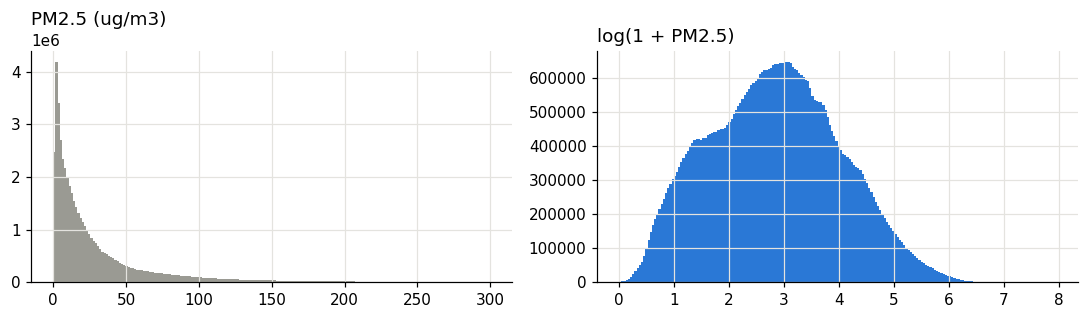

skewness: raw 5.1, log 0.13


In [5]:
allpm = np.concatenate([a.ravel() for a in pm.values()])
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(allpm, bins=200, range=(0, 300), color='#9a9a93'); ax[0].set_title('PM2.5 (ug/m3)', loc='left')
ax[1].hist(np.log1p(allpm), bins=200, color='#2a78d6'); ax[1].set_title('log(1 + PM2.5)', loc='left')
plt.tight_layout(); plt.show()
print(f'skewness: raw {((allpm - allpm.mean()) ** 3).mean() / allpm.std() ** 3:.1f}, log {((np.log1p(allpm) - np.log1p(allpm).mean()) ** 3).mean() / np.log1p(allpm).std() ** 3:.2f}')
del allpm

The raw distribution is strongly right-skewed (the December mean is 2.5 times its median). In
$\log(1+y)$ it is close to symmetric, which is why every model works in log space.

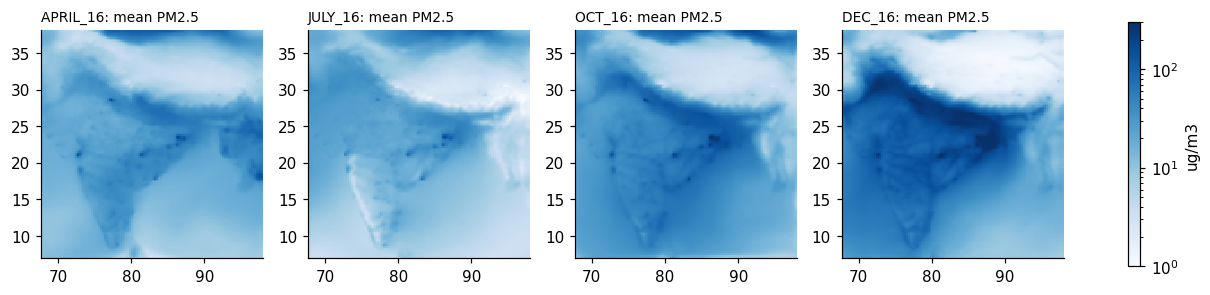

APRIL_16: highest monthly mean 177 ug/m3 at 23.54 N, 86.42 E
JULY_16: highest monthly mean 170 ug/m3 at 23.54 N, 86.42 E
OCT_16: highest monthly mean 327 ug/m3 at 23.54 N, 86.42 E
DEC_16: highest monthly mean 466 ug/m3 at 28.56 N, 77.30 E


In [6]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a_, (m, a) in zip(ax, pm.items()):
    im = a_.pcolormesh(lon, lat, np.maximum(a.mean(0), 0.5), shading='auto', cmap='Blues', norm=plt.matplotlib.colors.LogNorm(1, 300))
    a_.set_title(f'{m}: mean PM2.5', loc='left', fontsize=9); a_.set_aspect('equal'); a_.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='ug/m3'); plt.show()
for m, a in pm.items():
    mm = a.mean(0)
    i, j = np.unravel_index(np.argmax(mm), mm.shape)
    print(f'{m}: highest monthly mean {mm[i, j]:.0f} ug/m3 at {lat[i, j]:.2f} N, {lon[i, j]:.2f} E')

Pollution concentrates over the Indo-Gangetic Plain and the eastern coal belt, and the level changes
strongly with the season (July lowest, December highest). This is why inputs are normalized per cell
and a per-cell PM2.5 climatology is given as a static input.

## 4. Time: daily cycle and predictability

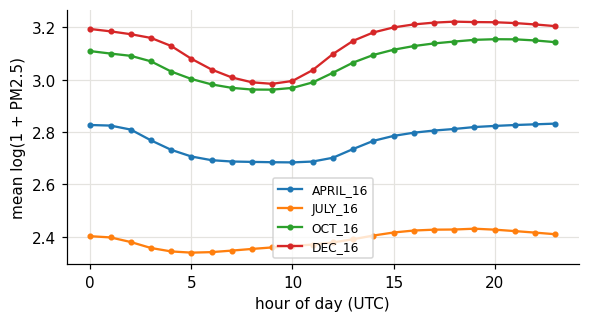

In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
for m, a in pm.items():
    dm = np.log1p(a).mean(axis=(1, 2))
    hours = np.arange(len(dm)) % 24
    ax.plot(range(24), [dm[hours == h].mean() for h in range(24)], marker='o', ms=3, label=m)
ax.set_xlabel('hour of day (UTC)'); ax.set_ylabel('mean log(1 + PM2.5)'); ax.legend(fontsize=8); plt.show()

In [8]:
def autocorr(lag):
    """Autocorrelation of log(1 + PM2.5) per cell (one mean and variance per series), averaged over cells and months."""
    out = []
    for a in pm.values():
        z = np.log1p(a.reshape(len(a), -1))
        z = z - z.mean(0)
        out.append(np.mean((z[lag:] * z[:-lag]).mean(0) / ((z * z).mean(0) + 1e-12)))
    return float(np.mean(out))


print('autocorrelation of log(1 + PM2.5):', {lag: round(autocorr(lag), 3) for lag in (1, 6, 12, 24)})

autocorrelation of log(1 + PM2.5): {1: 0.978, 6: 0.728, 12: 0.535, 24: 0.571}


sd of the change after h hours: {1: 0.101, 4: 0.286, 8: 0.419, 12: 0.485, 16: 0.505}


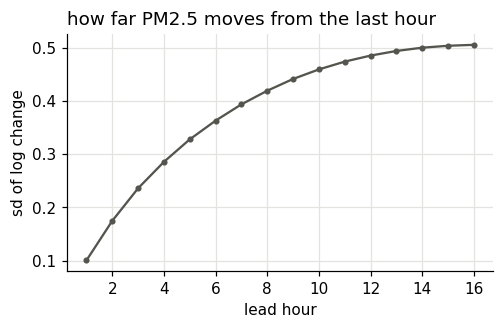

In [9]:
# change of log(1 + PM2.5) from the last input hour, on the 214 validation windows (every 7th cell)
dl = {h: [] for h in range(1, 17)}
for a in pm.values():
    T = len(a)
    for t0 in range(S.month_val_start(T), T - C.WIN + 1, C.VAL_STRIDE):
        last = np.log1p(a[t0 + C.T_IN - 1])
        for h in range(1, 17):
            dl[h].append((np.log1p(a[t0 + C.T_IN - 1 + h]) - last).ravel()[::7])
sd = [np.concatenate(dl[h]).std() for h in range(1, 17)]
print('sd of the change after h hours:', {h: round(float(sd[h - 1]), 3) for h in (1, 4, 8, 12, 16)})
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(range(1, 17), sd, marker='o', ms=3, color='#55554f'); ax.set_xlabel('lead hour'); ax.set_ylabel('sd of log change')
ax.set_title('how far PM2.5 moves from the last hour', loc='left'); plt.show()

PM2.5 one hour later is almost the same as now, so persistence is a strong forecast at short leads and
every network predicts the change from the last hour. The change grows about five-fold by hour 16,
which is why later lead hours get more weight in the loss.

## 5. Wind and transport

In [10]:
ws_all = []
for m in C.MONTHS:
    T = pm[m].shape[0]
    vb = S.month_val_start(T)
    u = np.load(os.path.join(C.RAW, m, 'u10.npy'))[:vb]
    v = np.load(os.path.join(C.RAW, m, 'v10.npy'))[:vb]
    ws_all.append(np.sqrt(u ** 2 + v ** 2).ravel())
ws = np.concatenate(ws_all)
mean_ws, rms_ws = ws.mean(), np.sqrt((ws ** 2).mean())
print(f'10-m wind over the training period: mean {mean_ws:.2f} m/s, RMS {rms_ws:.2f} m/s')
for name, w in (('mean', mean_ws), ('RMS', rms_ws)):
    print(f'  at the {name} wind, PM2.5 travels {w * 16 * 3.6:.0f} km in 16 h = {w * 16 * 3.6 / 25:.1f} cells of 25 km')
del ws, ws_all

10-m wind over the training period: mean 4.24 m/s, RMS 4.97 m/s
  at the mean wind, PM2.5 travels 244 km in 16 h = 9.8 cells of 25 km
  at the RMS wind, PM2.5 travels 286 km in 16 h = 11.5 cells of 25 km


Transport over 16 hours reaches about 10 to 12 cells. A network needs a receptive field of that size,
not a global one, and an advection channel gives it the first-order transport term directly.

## 6. Emission fields

In [11]:
for f in sorted(os.listdir(month_dir)):
    if f.endswith('.npy') and f.replace('.npy', '') not in C.FEATS:
        a = np.load(os.path.join(month_dir, f), mmap_mode='r')
        if a.dtype.kind not in 'fiu':
            print(f'{f:18s} text values, first {a[0]!s}, last {a[-1]!s}')
            continue
        print(f'{f:18s} max {float(np.max(a)):.2e}  share non-zero {float((np.asarray(a) != 0).mean()):.3f}')

NH3.npy            max 2.09e-08  share non-zero 0.975


NMVOC_e.npy        max 8.69e-09  share non-zero 0.962


NMVOC_finn.npy     max 7.05e-06  share non-zero 0.043
NOx.npy            max 7.98e-08  share non-zero 0.975


PM25.npy           max 1.43e-07  share non-zero 0.975
SO2.npy            max 3.76e-08  share non-zero 0.955
bio.npy            max 8.23e-09  share non-zero 0.373
time.npy           text values, first 2016-04-01T00:00:00, last 2016-04-30T18:00:00


The emission fields are tiny (about 1e-8 to 1e-7) and are not used as inputs. `time.npy` holds the
timestamps of the training months; the test windows have none.

## 7. What the data showed and what it changed

| Finding | What the pipeline does |
|:--|:--|
| right-skewed PM2.5 | works in log(1 + PM2.5) |
| PM2.5 one hour later is almost unchanged; the change grows with lead time | predicts the change from the last hour; weights later hours more |
| about 10 cells of transport in 16 h | advection channel; a local receptive field suffices |
| strong daily cycle; test windows have no clock | estimated start hour; diurnal-anomaly channel |
| hotspots and strong seasonal levels | per-cell normalization; static climatology |
| emission fields near zero | not used |